# Esercizio 1 — soluzione dei punti 1–3

:::{important} Archivio: versione a 5 punti
Questo notebook risolve la versione dell'esercizio a 5 punti
(`Exercise-MD.pdf`), arrivata per errore, **non** la consegna d'esame. La
consegna è risolta nel notebook
[Exercise 1 (PART 1 + 2)](../esame/esercizio1_part1_2.ipynb); vedi anche
l'[archivio](../../book/appendici/archivio_esercizio1_5_punti.md).
:::

*MD simulations of LJ-Ag*: la versione da presentare, punto per punto. Il
testo completo e le note di lettura sono nell'[archivio](../../book/appendici/archivio_esercizio1_5_punti.md);
le analisi più estese sono nei notebook dei
[punti 1–2](punti_1_2_passo_temporale.ipynb) e della
[steepest descent](../laboratori/steepest_descent.ipynb).

| | Richiesta | Dove |
|---|---|---|
| **0** | modello: LJ, taglio netto o raccordo $P_7$; `calcEnergy`, `calcForces` | §0 |
| **1** | taglio netto: $\Delta t$ ottimale a 50 K; a 500 K nessun $\Delta t$ basta | §1 |
| **2** | raccordo $P_7$: coerenza a 50 K; $\Delta t$ ottimale a 500, 1000, 2000 K | §2 |
| **3.0** | *steepest descent* fino a $F_\text{max}<10^{-3}$ eV/Å | §3.0 |
| **3** | 10 ps dal minimo: $\langle T\rangle$ contro $T_\text{ini}$; traiettorie di centro e vertici | §3 |

**Sistema.** Cluster di 256 atomi di Ag (fcc, $4\times4\times4$ celle,
$a=4.1604$ Å), **senza PBC**: il punto 3 parla di centro del cluster e di
vertici del cubo. LJ con $\varepsilon=0.345$ eV, $\sigma=2.644$ Å,
$r_c=4.5$ Å; $t_{th}=3$ ps scartati dalle medie. Criterio sul passo:
$\delta E/|\langle E\rangle|<10^{-5}$, con $\delta E$ la deviazione standard
di $E_\text{tot}$ dopo $t_{th}$.

In [1]:
import sys
from pathlib import Path


def _setup_path():
    root = Path.cwd()
    for _ in range(10):
        if (root / "pyproject.toml").exists():
            break
        root = root.parent
    for sub in ("src", "materials"):
        path = str(root / sub)
        if path not in sys.path:
            sys.path.insert(0, path)
    return root


ROOT = _setup_path()

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter, NullFormatter
from poly7 import poly7  # file del corso: materials/poly7.py

from computational_course.fcc_lattice import fcc_supercell
from computational_course.lennard_jones import build_neighbor_list
from computational_course.md import assign_vel, instantaneous_T, kinetic_energy
from computational_course.md_p7 import (
    lj_p7_model,
    production_stats,
    remove_angular_momentum,
    run_nve,
    steepest_descent,
)

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.grid": True,
                     "grid.alpha": 0.25, "axes.axisbelow": True})

EPSILON, SIGMA = 0.345, 2.644  # eV, Å
RC, RP = 4.5, 4.2  # Å: raggio di taglio e inizio del raccordo P7
T_TH_PS, NSTEPS, SOGLIA = 3.0, 5000, 1e-5  # termalizzazione, passi per prova, criterio
C_STEEP, F_TOL = 0.005, 1e-3  # steepest descent: Å²/eV, eV/Å
MASS = 108.0 * 1.66e-27 / 16.0  # massa Ag in unità di codice (eV s²/Å²)
FS, A_AG, SEED = 1e-15, 4.1604, 33282739

lp = poly7(EPSILON, SIGMA, RC, RP)
P7 = np.array([lp.A, lp.B, lp.C, lp.D, lp.E, lp.F, lp.G, lp.H])  # termini r^0 ... r^7
polyval, polyder = np.polynomial.polynomial.polyval, np.polynomial.polynomial.polyder
dP7 = polyder(P7)

FILE_256 = ROOT / "data" / "raw" / "fcc100a256.txt"
pos0 = np.loadtxt(FILE_256) if FILE_256.exists() else fcc_supercell(A_AG, 4, 4, 4)[0]
natoms = len(pos0)

COLORI = {50.0: "#2a78d6", 500.0: "#eb6834", 1000.0: "#1baf7a", 2000.0: "#eda100"}
GRIGIO = "#52514e"

## 0. Il modello: `calcEnergy` e `calcForces`

$$
\phi(r)=\begin{cases}
4\varepsilon\left[(\sigma/r)^{12}-(\sigma/r)^6\right] & r\le r_p\\
P_7(r)=A+Br+\dots+Hr^7 & r_p<r<r_c\quad\text{(solo con il raccordo)}\\
0 & r\ge r_c
\end{cases}
\qquad
\mathbf F(k)=\sum_{j}f(r_{kj})\,\frac{\mathbf r_k-\mathbf r_j}{r_{kj}},\quad f=-\frac{\mathrm d\phi}{\mathrm dr}
$$

- **Taglio netto:** $\phi_{LJ}$ fino a $r_c$. In $r_c$ l'energia salta di
  $|\phi_{LJ}(r_c)|=0.054$ eV.
- **Raccordo $P_7$:** tra $r_p$ e $r_c$; $\phi$, $\phi'$, $\phi''$ e
  $\phi'''$ sono continue in $r_p$ e nulle in $r_c$. I coefficienti A…H
  vengono da `poly7.py`.
- **Liste dei vicini:** `calcNbrs` restituisce `nNbrs` e `whichNbrs`. Ogni
  coppia compare due volte, quindi l'energia va divisa per 2.

In [2]:
def calcNbrs(pos):
    # liste dei vicini entro r_c (cluster: nessuna PBC)
    return build_neighbor_list(pos, RC)


def _coppie(pos, nNbrs, whichNbrs, raccordo):
    # per ogni coppia (i, j) della lista: r_ij, φ(r) e f(r) = -dφ/dr
    piena = np.arange(whichNbrs.shape[1])[None, :] < nNbrs[:, None]
    i, j = np.nonzero(piena)[0], whichNbrs[piena]
    rij = pos[i] - pos[j]
    r = np.sqrt(rij[:, 0] ** 2 + rij[:, 1] ** 2 + rij[:, 2] ** 2)
    sr6 = (SIGMA / r) ** 6
    phi = 4 * EPSILON * (sr6**2 - sr6)
    f = 24 * EPSILON * (2 * sr6**2 - sr6) / r
    if raccordo:
        coda = r > RP
        phi[coda] = polyval(r[coda], P7)  # P7(r)
        f[coda] = -polyval(r[coda], dP7)  # -P7'(r)
    return i, rij, r, phi, f


def calcEnergy(pos, nNbrs, whichNbrs, raccordo=True):
    _, _, _, phi, _ = _coppie(pos, nNbrs, whichNbrs, raccordo)
    return 0.5 * phi.sum()  # ogni coppia compare due volte


def calcForces(pos, nNbrs, whichNbrs, raccordo=True):
    i, rij, r, _, f = _coppie(pos, nNbrs, whichNbrs, raccordo)
    forces = np.zeros_like(pos)
    np.add.at(forces, i, (f / r)[:, None] * rij)  # F(i) += f(r_ij) (r_i - r_j)/r_ij
    return forces


# le MD lunghe usano la stessa fisica in versione compilata (Numba, modulo md_p7)
netto = lj_p7_model(SIGMA, EPSILON, RC)
raccordo = lj_p7_model(SIGMA, EPSILON, RC, rp=RP, p7=P7)

prova_pos = pos0 + 0.1 * np.random.default_rng(1).standard_normal(pos0.shape)
nN, wN = calcNbrs(prova_pos)
for nome, modello, flag in (("taglio netto", netto, False), ("raccordo P7", raccordo, True)):
    e_num, f_num, _ = modello(prova_pos)
    print(f"{nome:12s}: |ΔE| = {abs(calcEnergy(prova_pos, nN, wN, flag) - e_num):.0e} eV, "
          f"max|ΔF| = {np.abs(calcForces(prova_pos, nN, wN, flag) - f_num).max():.0e} eV/Å "
          "(calcForces contro la versione compilata)")

continuita = pd.DataFrame(
    {"P7^(k)(r_p)": [polyval(RP, polyder(P7, k)) for k in range(4)],
     "φ_LJ^(k)(r_p)": 4 * EPSILON * np.array([
         SIGMA**12 / RP**12 - SIGMA**6 / RP**6,
         -12 * SIGMA**12 / RP**13 + 6 * SIGMA**6 / RP**7,
         156 * SIGMA**12 / RP**14 - 42 * SIGMA**6 / RP**8,
         -2184 * SIGMA**12 / RP**15 + 336 * SIGMA**6 / RP**9]),
     "P7^(k)(r_c)": [polyval(RC, polyder(P7, k)) for k in range(4)]},
    index=pd.Index(range(4), name="derivata k"),
)
display(continuita.style.format("{:.3e}").set_caption("Raccordo P7: continuità in r_p, zero in r_c"))

taglio netto: |ΔE| = 3e-13 eV, max|ΔF| = 1e-14 eV/Å (calcForces contro la versione compilata)
raccordo P7 : |ΔE| = 3e-13 eV, max|ΔF| = 1e-14 eV/Å (calcForces contro la versione compilata)


,P7^(k)(r_p),φ_LJ^(k)(r_p),P7^(k)(r_c)
derivata k,,,
0,-8.055e-02,-8.055e-02,-5.662e-06
1,1.074e-01,1.074e-01,-5.186e-06
2,-1.572e-01,-1.572e-01,-3.278e-06
3,2.319e-01,2.319e-01,-1.669e-06


Il raccordo rispetta le condizioni fino a qualche $10^{-6}$. È un limite
numerico, non un errore: i coefficienti arrivano a $10^8$ con segni alterni,
e nella somma si perdono cifre per cancellazione. Il residuo è 10 000 volte
più piccolo del salto del taglio netto.

## 1. Punto 1 — taglio netto

**Richiesta.** Trovare il $\Delta t$ ottimale a $T_\text{ini}=50$ K (prove
tra 1 e 25 fs, 5000 passi ciascuna), poi mostrare che a 500 K il criterio non
si rispetta comunque si riduca il passo.

**Come.** Si parte dal reticolo del file (il testo chiede la minimizzazione
solo dal punto 3). Per ogni $\Delta t$ si fa una MD NVE con *velocity
Verlet*, sempre con le stesse velocità iniziali, e si calcola
$\delta E/|\langle E\rangle|$ dopo $t_{th}$. Si contano anche le coppie che
**attraversano $r_c$**. Sotto 1 fs (0.5 e 0.25 fs) 5000 passi non bastano a
superare $t_{th}$: si tiene la durata della prova a 1 fs (5 ps) e si
aumentano i passi.

,Δt validi,Δt ottimale,δE/|⟨E⟩| a 1 fs,δE/|⟨E⟩| a 0.25 fs,attraversamenti di r_c (1 fs)
T_ini,,,,,
50 K,1–20 fs,20 fs,2.2e-08,—,0
500 K,nessuno,nessuno,1.6e-04,1.5e-04,243


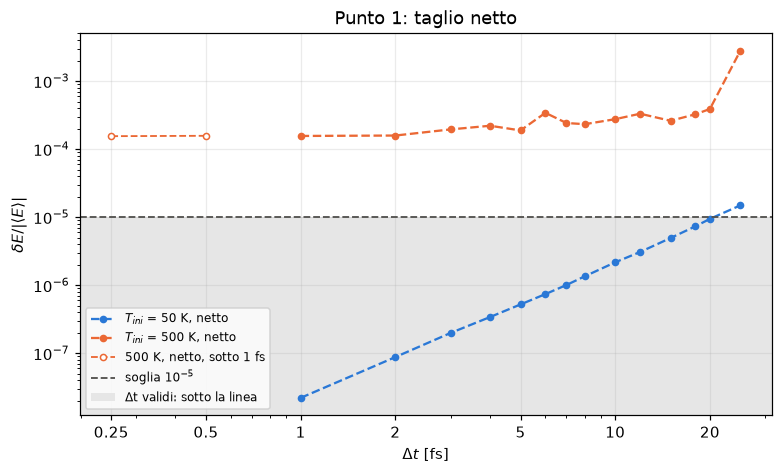

In [3]:
DTS_FS = [1, 2, 3, 4, 5, 6, 7, 8, 10, 12, 15, 18, 20, 25]


def prova(modello, t_ini, dt_fs, nsteps=NSTEPS, pos=pos0, vel=None):
    # una MD NVE; medie dopo t_th
    vel = assign_vel(natoms, MASS, t_ini, seed=SEED) if vel is None else vel
    res = run_nve(pos, vel, MASS, dt_fs * FS, nsteps, modello)
    return {"dt": dt_fs, **production_stats(res, int(round(T_TH_PS * 1000 / dt_fs))),
            "n_cross": res["n_cross"], "res": res}


def validi(prove):
    return [p["dt"] for p in prove if p["dE_rel"] < SOGLIA]


def testo_validi(prove):
    ok = validi(prove)
    return f"{ok[0]:g}–{ok[-1]:g} fs" if ok else "nessuno"


def ottimale(prove):
    ok = validi(prove)
    return f"{max(ok):g} fs" if ok else "nessuno"


def grafico_dt(ax, scansioni, stile, etichetta):
    for t, prove in scansioni.items():
        ax.plot([p["dt"] for p in prove], [p["dE_rel"] for p in prove], stile, color=COLORI[t],
                ms=4, lw=1.5, label=f"$T_{{ini}}$ = {t:g} K, {etichetta}")


def assi_dt(ax, titolo):
    ax.set(xscale="log", yscale="log", xlabel=r"$\Delta t$ [fs]",
           ylabel=r"$\delta E/|\langle E\rangle|$", title=titolo)
    ax.axhline(SOGLIA, color=GRIGIO, ls="--", lw=1.2, label="soglia $10^{-5}$")
    y_lo, y_hi = ax.get_ylim()
    ax.axhspan(y_lo, SOGLIA, color="0.9", lw=0, zorder=0, label="Δt validi: sotto la linea")
    ax.set_ylim(y_lo, y_hi)
    ax.set_xticks([1, 2, 3, 5, 8, 10, 15, 20, 25])
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:g}"))
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.legend(fontsize=8)


punto1 = {t: [prova(netto, t, dt) for dt in DTS_FS] for t in (50.0, 500.0)}
sotto_fs = {dt: prova(netto, 500.0, dt, nsteps=int(round(5000 / dt))) for dt in (0.5, 0.25)}

display(pd.DataFrame(
    {"Δt validi": [testo_validi(punto1[t]) for t in punto1],
     "Δt ottimale": [ottimale(punto1[t]) for t in punto1],
     "δE/|⟨E⟩| a 1 fs": [f"{punto1[t][0]['dE_rel']:.1e}" for t in punto1],
     "δE/|⟨E⟩| a 0.25 fs": ["—", f"{sotto_fs[0.25]['dE_rel']:.1e}"],
     "attraversamenti di r_c (1 fs)": [punto1[t][0]["n_cross"] for t in punto1]},
    index=pd.Index([f"{t:g} K" for t in punto1], name="T_ini"),
).style.set_caption("Punto 1 — taglio netto"))

fig, ax = plt.subplots(figsize=(7, 4.2), constrained_layout=True)
grafico_dt(ax, punto1, "o--", "netto")
ax.plot([0.25, 0.5], [sotto_fs[0.25]["dE_rel"], sotto_fs[0.5]["dE_rel"]], "o--",
        color=COLORI[500.0], mfc="white", ms=4, lw=1.2, label="500 K, netto, sotto 1 fs")
assi_dt(ax, "Punto 1: taglio netto")
ax.set_xticks([0.25, 0.5, 1, 2, 5, 10, 20])
plt.show()

**Risultato.**

- **50 K:** sono validi tutti i passi da 1 a 20 fs, quindi il **$\Delta t$
  ottimale è 20 fs**. L'errore cresce come $\Delta t^2$ (integratore), e
  nessuna coppia attraversa $r_c$.
- **500 K:** **nessun passo è valido**. $\delta E/|\langle E\rangle|$ resta
  attorno a $1.6\times10^{-4}$ anche a 0.25 fs.

**Perché.** A 500 K gli atomi di superficie del cluster vibrano abbastanza da
portare coppie oltre $r_c$: più di 200 attraversamenti in 5 ps. Ogni
attraversamento cambia l'energia di 0.054 eV, qualunque sia $\Delta t$. È un
errore del **modello**, non dell'integratore, e ridurre il passo non lo
toglie.

## 2. Punto 2 — raccordo $P_7$

**Richiesta.** Con il raccordo $P_7$ (e le forze adattate, §0): verificare
che a 50 K il risultato sia coerente con il taglio netto, e trovare il
$\Delta t$ ottimale a 500, 1000 e 2000 K.

,Δt validi,Δt ottimale,⟨T⟩ a 1 fs [K],δE/|⟨E⟩| a 10 fs
T_ini = 50 K,,,,
taglio netto,1–20 fs,20 fs,28.4,2.17e-06
raccordo P7,1–20 fs,20 fs,28.5,2.23e-06


,Δt validi,Δt ottimale,δE/|⟨E⟩| al Δt ottimale,attraversamenti di r_c (1 fs)
T_ini (P7),,,,
500 K,1–6 fs,6 fs,8.6e-06,15
1000 K,1–4 fs,4 fs,7.8e-06,508
2000 K,1–3 fs,3 fs,9.6e-06,3701


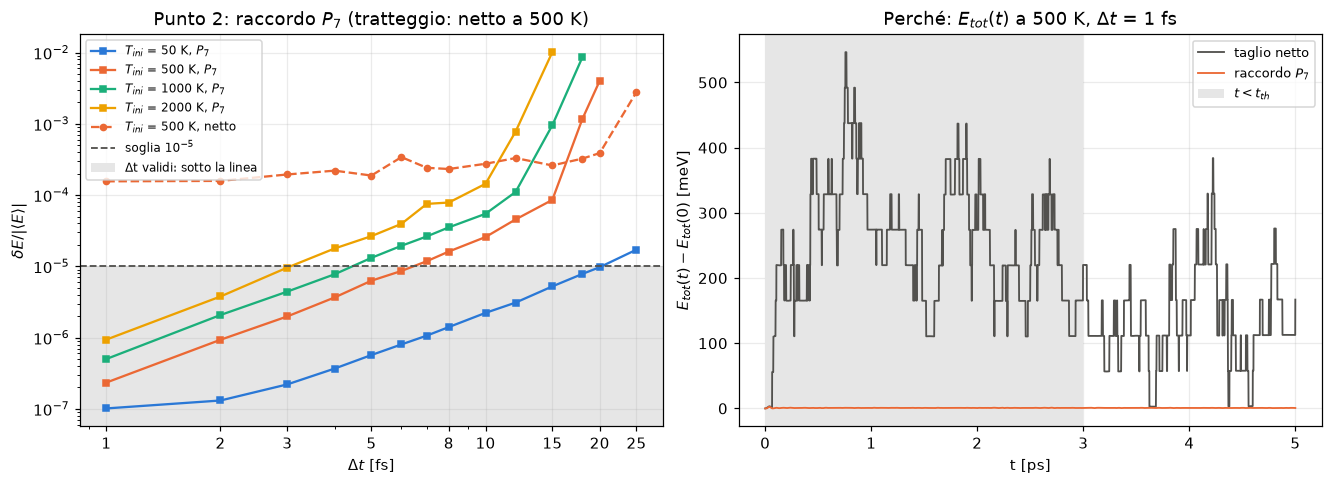

In [4]:
punto2 = {t: [prova(raccordo, t, dt) for dt in DTS_FS] for t in (50.0, 500.0, 1000.0, 2000.0)}

display(pd.DataFrame(
    {"Δt validi": [testo_validi(punto1[50.0]), testo_validi(punto2[50.0])],
     "Δt ottimale": [ottimale(punto1[50.0]), ottimale(punto2[50.0])],
     "⟨T⟩ a 1 fs [K]": [f"{punto1[50.0][0]['T_mean']:.1f}", f"{punto2[50.0][0]['T_mean']:.1f}"],
     "δE/|⟨E⟩| a 10 fs": [f"{punto1[50.0][8]['dE_rel']:.2e}", f"{punto2[50.0][8]['dE_rel']:.2e}"]},
    index=pd.Index(["taglio netto", "raccordo P7"], name="T_ini = 50 K"),
).style.set_caption("Punto 2a — coerenza a 50 K"))

display(pd.DataFrame(
    {"Δt validi": [testo_validi(punto2[t]) for t in (500.0, 1000.0, 2000.0)],
     "Δt ottimale": [ottimale(punto2[t]) for t in (500.0, 1000.0, 2000.0)],
     "δE/|⟨E⟩| al Δt ottimale": [f"{max(p['dE_rel'] for p in punto2[t] if p['dE_rel'] < SOGLIA):.1e}"
                                 for t in (500.0, 1000.0, 2000.0)],
     "attraversamenti di r_c (1 fs)": [punto2[t][0]["n_cross"] for t in (500.0, 1000.0, 2000.0)]},
    index=pd.Index(["500 K", "1000 K", "2000 K"], name="T_ini (P7)"),
).style.set_caption("Punto 2b — passo ottimale con il raccordo P7"))

fig, (ax_dt, ax_e) = plt.subplots(1, 2, figsize=(12, 4.3), constrained_layout=True)
grafico_dt(ax_dt, punto2, "s-", "$P_7$")
grafico_dt(ax_dt, {500.0: punto1[500.0]}, "o--", "netto")
assi_dt(ax_dt, "Punto 2: raccordo $P_7$ (tratteggio: netto a 500 K)")
for p, nome, colore in ((punto1[500.0][0], "taglio netto", GRIGIO),
                        (punto2[500.0][0], "raccordo $P_7$", COLORI[500.0])):
    ax_e.plot(p["res"]["time_ps"], (p["res"]["etot"] - p["res"]["etot"][0]) * 1e3,
              lw=1.2, color=colore, label=nome)
ax_e.axvspan(0, T_TH_PS, color="0.9", lw=0, label="$t<t_{th}$")
ax_e.set(xlabel="t [ps]", ylabel=r"$E_{tot}(t)-E_{tot}(0)$ [meV]",
         title=r"Perché: $E_{tot}(t)$ a 500 K, $\Delta t$ = 1 fs")
ax_e.legend(fontsize=8.5)
plt.show()

**Risultato.**

- **Coerenza a 50 K:** stessi passi validi (1–20 fs), stesso $\Delta t$
  ottimale (20 fs), stesso $\langle T\rangle$, stesso $\delta E$ entro pochi
  punti percentuali. A questa temperatura le coppie non arrivano a $r_c$, e i
  due modelli danno la stessa statistica.
- **Passo ottimale:** **6 fs a 500 K, 4 fs a 1000 K, 3 fs a 2000 K**. Più
  la temperatura è alta, più gli atomi sono veloci, e più il passo va
  ridotto. A 2000 K e 3 fs il valore è a ridosso della soglia: l'ho
  controllato con 4 semi diversi nel
  [notebook dei punti 1–2](punti_1_2_passo_temporale.ipynb), §4, e regge.

**Perché funziona.** A destra, con il taglio netto $E_\text{tot}$ procede a
**gradini**: ogni gradino è un attraversamento di $r_c$. Con il $P_7$ le
coppie attraversano ancora $r_c$, ma lì energia e forza sono già nulle, e la
curva resta piatta.

## 3.0 *Steepest descent*

**Richiesta (dal punto 3 in poi).** Partire da un minimo dell'energia:
$\mathbf r(k)\leftarrow\mathbf r(k)+C\,\mathbf F(k)$ con $C=0.005$ Å²/eV,
fino a $\max_k|\mathbf F(k)|<10^{-3}$ eV/Å. (Il testo scrive «Å/eV», ma
l'unità di $C$ è Å²/eV; teoria nel
[capitolo dedicato](../../book/teoria/06_steepest_descent.md).)

**Come.** È lo pseudocodice della slide 38, con le **stesse** `calcNbrs` e
`calcForces` del §0.

convergenza in 598 iterazioni: E -453.4502 -> -453.6714 eV (ΔE = -0.2212 eV), F_max 0.197 -> 1.0e-03 eV/Å
energia sempre decrescente: True; stesso minimo della versione compilata: 5e-15 Å


,primi vicini,quanti,|δr| medio [Å],|δr| max [Å],δr radiale medio [Å]
atomi,,,,,
interno,12,108,0.017,0.039,-0.016
faccia,8,108,0.023,0.041,-0.004
spigolo,5,36,0.017,0.036,-0.015
vertice,3,4,0.050,0.050,-0.050


traslazione del centro di massa: 1e-14 Å; rotazione |Σ (r-r_cm) × δr|: 2e-13 Å²


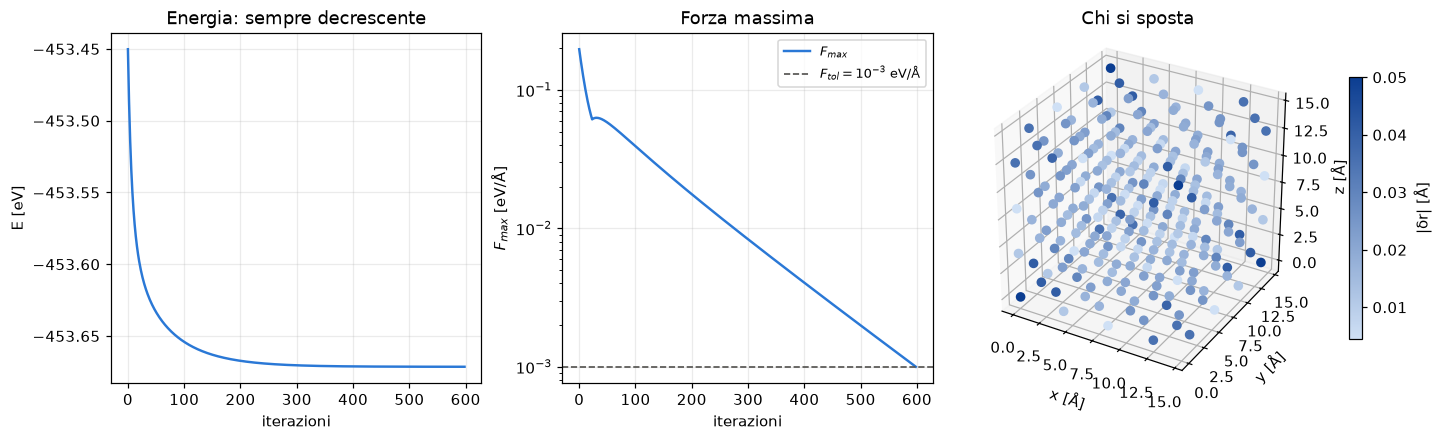

In [5]:
Csteep, ftoll, maxStep = C_STEEP, F_TOL, 10_000
pos = pos0.copy()
energia, forza_max = [], []
for iStep in range(maxStep):
    nNbrs, whichNbrs = calcNbrs(pos)  # liste dei vicini
    forces = calcForces(pos, nNbrs, whichNbrs)  # la stessa funzione della MD (con il P7)
    maxf = np.max(np.sqrt(forces[:, 0] ** 2 + forces[:, 1] ** 2 + forces[:, 2] ** 2))
    energia.append(calcEnergy(pos, nNbrs, whichNbrs))
    forza_max.append(maxf)
    if maxf < ftoll:
        break  # convergenza
    pos = pos + Csteep * forces
pos_min, e_min = pos, energia[-1]
print(f"convergenza in {iStep} iterazioni: E {energia[0]:.4f} -> {e_min:.4f} eV "
      f"(ΔE = {e_min - energia[0]:.4f} eV), F_max {forza_max[0]:.3f} -> {maxf:.1e} eV/Å")
print(f"energia sempre decrescente: {bool(np.all(np.diff(energia) <= 0))}; "
      f"stesso minimo della versione compilata: "
      f"{np.abs(pos_min - steepest_descent(pos0, raccordo, c=C_STEEP, ftol=F_TOL)['pos']).max():.0e} Å")

# chi si sposta? atomi divisi per numero di primi vicini nel reticolo ideale
d0 = np.linalg.norm(pos0[:, None] - pos0[None], axis=-1)
coord = np.count_nonzero((d0 > 0.1) & (d0 < 0.5 * (A_AG / np.sqrt(2) + A_AG)), axis=1)
spost = pos_min - pos0
centro = pos0.mean(axis=0)
radiale = np.einsum("ij,ij->i", spost, pos0 - centro) / np.linalg.norm(pos0 - centro, axis=1)
nomi = {12: "interno", 8: "faccia", 5: "spigolo", 3: "vertice"}
display(pd.DataFrame(
    [{"atomi": nomi[z], "primi vicini": z, "quanti": int(np.count_nonzero(coord == z)),
      "|δr| medio [Å]": f"{np.linalg.norm(spost[coord == z], axis=1).mean():.3f}",
      "|δr| max [Å]": f"{np.linalg.norm(spost[coord == z], axis=1).max():.3f}",
      "δr radiale medio [Å]": f"{radiale[coord == z].mean():+.3f}"} for z in (12, 8, 5, 3)]
).set_index("atomi").style.set_caption("Spostamenti dal reticolo ideale al minimo"))
print(f"traslazione del centro di massa: {np.linalg.norm(pos_min.mean(0) - centro):.0e} Å; "
      f"rotazione |Σ (r-r_cm) × δr|: {np.linalg.norm(np.cross(pos0 - centro, spost).sum(0)):.0e} Å²")

fig = plt.figure(figsize=(13, 3.9), constrained_layout=True)
ax_e = fig.add_subplot(1, 3, 1)
ax_f = fig.add_subplot(1, 3, 2)
ax_3d = fig.add_subplot(1, 3, 3, projection="3d")
ax_e.plot(energia, color=COLORI[50.0], lw=1.6)
ax_e.set(xlabel="iterazioni", ylabel="E [eV]", title="Energia: sempre decrescente")
ax_f.semilogy(forza_max, color=COLORI[50.0], lw=1.6, label=r"$F_{max}$")
ax_f.axhline(F_TOL, color=GRIGIO, ls="--", lw=1.1, label=r"$F_{tol}=10^{-3}$ eV/Å")
ax_f.set(xlabel="iterazioni", ylabel=r"$F_{max}$ [eV/Å]", title="Forza massima")
ax_f.legend(fontsize=8.5)
blu = LinearSegmentedColormap.from_list("blu", ["#cfe0f5", "#0b3d91"])
sc = ax_3d.scatter(*pos_min.T, c=np.linalg.norm(spost, axis=1), cmap=blu, s=28, depthshade=False)
fig.colorbar(sc, ax=ax_3d, shrink=0.75, label="|δr| [Å]")
ax_3d.set(xlabel="x [Å]", ylabel="y [Å]", zlabel="z [Å]", title="Chi si sposta")
ax_3d.set_box_aspect((1, 1, 1))
plt.show()

**Risultato.**

- La discesa converge in circa 600 iterazioni e l'energia scende a ogni
  passo. In tutto guadagna 0.22 eV, meno di 1 meV per atomo.
- Il cluster si **contrae** di poco: tutti gli spostamenti radiali sono
  negativi, e il più grande è $0.05$ Å, ai **vertici**. Gli atomi con meno
  vicini (vertici, spigoli) si avvicinano a quelli rimasti.
- Il centro di massa non si muove e il cluster non ruota: con forze di coppia
  centrali, $\sum_k\mathbf F(k)=0$ e anche il momento totale è nullo.
- Solo **4** degli 8 vertici del cubo sono occupati da un atomo: è la
  costruzione dei file del corso.

## 3. Punto 3 — temperatura ed equipartizione

**Richiesta.** Partendo dal minimo, run da 10 ps a $T_\text{ini}=50$, 500,
1000 e 2000 K con i passi ottimali del punto 2. Tracciare $\langle T\rangle$
contro $T_\text{ini}$, verificare $\langle T\rangle=T_\text{ini}/2$ e
spiegarlo. Confrontare le traiettorie degli atomi al centro e ai vertici, alla
temperatura più bassa e a quella più alta.

**Come.**

- Raccordo $P_7$; $\Delta t$ dal punto 2: 20, 6, 4 e 3 fs.
- Velocità con quantità di moto **e momento angolare** nulli, riscalate a
  $T_\text{ini}$ (vedi la nota sotto).
- $\langle T\rangle$ calcolato su 3–10 ps e mediato su 4 semi delle velocità
  iniziali.

,Δt [fs],passi,⟨T⟩ [K],⟨T⟩ / (T_ini/2),δE/|⟨E⟩| (max sui semi),atomi lontani dal sito a 10 ps
T_ini [K],,,,,,
50,20,500,25.1 ± 0.0,1.006,8.9e-06,0.0
500,6,1667,258.0 ± 0.1,1.032,8.6e-06,0.0
1000,4,2500,501.6 ± 0.7,1.003,8.8e-06,0.2
2000,3,3333,911.0 ± 2.1,0.911,1.0e-05,6.5


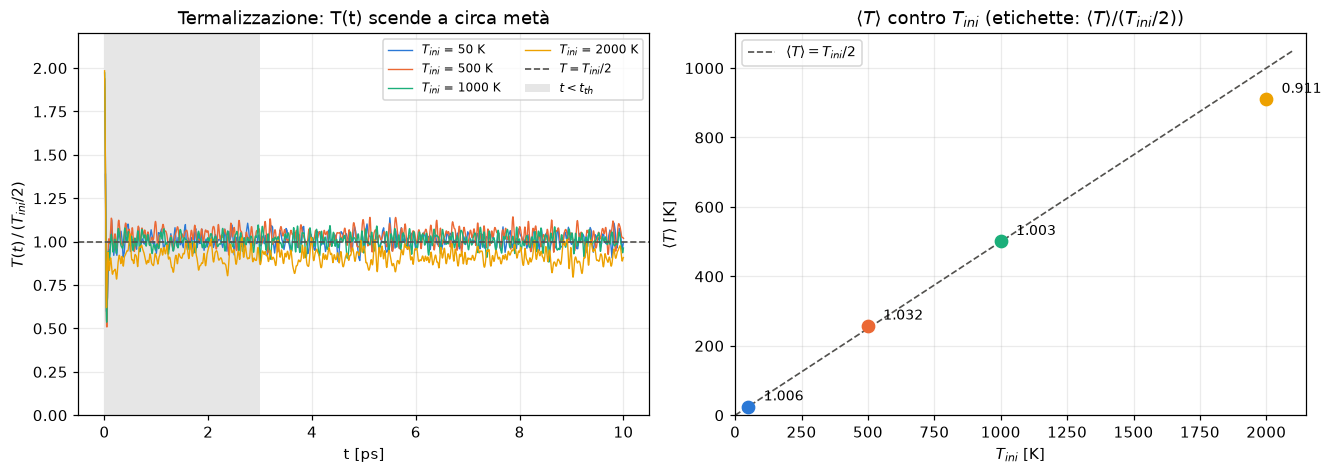

In [6]:
DT_OTT = {t: max(validi(punto2[t])) for t in (50.0, 500.0, 1000.0, 2000.0)}
SEMI = (SEED, 20260101, 555000111, 987654321)


def velocita_iniziali(t_ini, seed):
    # P = 0 (assign_vel), L = 0, poi riscalate esattamente a T_ini
    vel = remove_angular_momentum(pos_min, assign_vel(natoms, MASS, t_ini, seed=seed), MASS)
    return vel * np.sqrt(t_ini / instantaneous_T(kinetic_energy(vel, MASS), natoms))


punto3, traiettorie = {}, {}
for t_ini, dt in DT_OTT.items():
    nsteps = int(round(10_000 / dt))
    punto3[t_ini] = []
    for seed in SEMI:
        res = run_nve(pos_min, velocita_iniziali(t_ini, seed), MASS, dt * FS, nsteps, raccordo,
                      sample_every=1 if seed == SEED else 0)  # traiettoria completa solo per un seme
        punto3[t_ini].append({**production_stats(res, int(round(T_TH_PS * 1000 / dt))), "res": res})
    traiettorie[t_ini] = punto3[t_ini][0]["res"]  # seme di riferimento, per i grafici

r1 = A_AG / np.sqrt(2)
tab3 = pd.DataFrame(
    [{"T_ini [K]": t, "Δt [fs]": DT_OTT[t], "passi": int(round(10_000 / DT_OTT[t])),
      "⟨T⟩ [K]": f"{np.mean([p['T_mean'] for p in punto3[t]]):.1f} ± "
                 f"{np.std([p['T_mean'] for p in punto3[t]]):.1f}",
      "⟨T⟩ / (T_ini/2)": f"{np.mean([p['T_mean'] for p in punto3[t]]) / (t / 2):.3f}",
      "δE/|⟨E⟩| (max sui semi)": f"{max(p['dE_rel'] for p in punto3[t]):.1e}",
      "atomi lontani dal sito a 10 ps": f"{np.mean([np.count_nonzero(np.linalg.norm(p['res']['pos'] - pos_min, axis=1) > r1 / 2) for p in punto3[t]]):.1f}"}
     for t in DT_OTT]
).set_index("T_ini [K]")
display(tab3.style.format_index("{:g}").set_caption(
    "Punto 3 — 10 ps dal minimo (media ± deviazione standard su 4 semi); "
    "«lontani dal sito»: spostati di oltre r1/2 = 1.47 Å"))

fig, (ax_t, ax_m) = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)
for t, res in traiettorie.items():
    ax_t.plot(res["time_ps"], res["T"] / (t / 2), color=COLORI[t], lw=0.9, label=f"$T_{{ini}}$ = {t:g} K")
ax_t.axhline(1.0, color=GRIGIO, ls="--", lw=1.1, label=r"$T = T_{ini}/2$")
ax_t.axvspan(0, T_TH_PS, color="0.9", lw=0, label="$t<t_{th}$")
ax_t.set(xlabel="t [ps]", ylabel=r"$T(t)\,/\,(T_{ini}/2)$", ylim=(0, 2.2),
         title="Termalizzazione: T(t) scende a circa metà")
ax_t.legend(fontsize=8, ncol=2)
t_ini = np.array(list(DT_OTT))
t_med = np.array([np.mean([p["T_mean"] for p in punto3[t]]) for t in DT_OTT])
t_std = np.array([np.std([p["T_mean"] for p in punto3[t]]) for t in DT_OTT])
ax_m.plot([0, 2100], [0, 1050], "--", color=GRIGIO, lw=1.1, label=r"$\langle T\rangle = T_{ini}/2$")
for t, m, s in zip(t_ini, t_med, t_std):
    ax_m.errorbar(t, m, yerr=s, fmt="o", ms=8, color=COLORI[t], capsize=3)
    ax_m.annotate(f"{m / (t / 2):.3f}", (t, m), textcoords="offset points", xytext=(10, 4), fontsize=9)
ax_m.set(xlabel=r"$T_{ini}$ [K]", ylabel=r"$\langle T\rangle$ [K]", xlim=(0, 2150), ylim=(0, 1100),
         title=r"$\langle T\rangle$ contro $T_{ini}$ (etichette: $\langle T\rangle/(T_{ini}/2)$)")
ax_m.legend(fontsize=9, loc="upper left")
plt.show()

**Perché $\langle T\rangle\approx T_\text{ini}/2$.**

1. Si parte dal **minimo**: $U=U_\text{min}$, e tutta l'energia in eccesso è
   cinetica, $K_0=\tfrac32Nk_BT_\text{ini}$.
2. In NVE l'energia si conserva:
   $U_\text{min}+K_0=U_\text{min}+\langle K\rangle+\langle U-U_\text{min}\rangle$.
3. Per piccole oscillazioni attorno al minimo il cristallo è un insieme di
   oscillatori armonici, e per ognuno l'energia media si divide **a metà** tra
   cinetica e potenziale: $\langle K\rangle=\langle U-U_\text{min}\rangle$
   (equipartizione, o teorema del viriale con $U\propto x^2$).
4. Quindi $\langle K\rangle=K_0/2$, cioè $\langle T\rangle=T_\text{ini}/2$.
   Per avere una temperatura $T$ si parte da $T_\text{ini}=2T$.

**Dove vale.** A 50 K entro l'1%. (A 2000 K con 3 fs un seme arriva a
$\delta E/|\langle E\rangle|\approx10^{-5}$, sulla soglia; $\langle T\rangle$
cambia comunque di pochi K tra i semi.) A 2000 K $\langle T\rangle$ è circa il 9%
**sotto** $T_\text{ini}/2$. Ad alta temperatura le oscillazioni sono ampie, e il
potenziale LJ è più **morbido** del suo sviluppo armonico: i legami si
allungano verso la parte piatta dell'attrazione, e alcuni atomi di superficie
lasciano il loro sito (ultima colonna della tabella). L'energia potenziale
prende più della metà, e la temperatura resta sotto $T_\text{ini}/2$.

A 500 K $\langle T\rangle$ è invece circa il 3% **sopra** $T_\text{ini}/2$.
Il controllo qui sotto mostra che è un effetto del raccordo: tra 4.2 e
4.5 Å il $P_7$ è molto curvo (fino a 5.9 eV/Å², contro 0.16 eV/Å² di LJ in
$r_p$) e a 500 K centinaia di coppie stanno in quella zona. Si comporta come
una molla più rigida, che prende meno energia potenziale. Con il taglio netto,
o con LJ senza taglio ($r_c=8$ Å), la stessa prova dà $\langle T\rangle$
sotto $T_\text{ini}/2$, come ci si aspetta da un potenziale anarmonico più
morbido.

In [7]:
lj_lungo = lj_p7_model(SIGMA, EPSILON, 8.0)  # LJ praticamente senza taglio
controllo = {}
for nome, modello in (("raccordo P7", raccordo), ("taglio netto", netto), ("LJ, r_c = 8 Å", lj_lungo)):
    minimo = steepest_descent(pos0, modello, c=C_STEEP, ftol=F_TOL)["pos"]
    riga = {}
    for t_ini in (500.0, 1000.0):
        vel = remove_angular_momentum(minimo, assign_vel(natoms, MASS, t_ini, seed=SEED), MASS)
        vel *= np.sqrt(t_ini / instantaneous_T(kinetic_energy(vel, MASS), natoms))
        res = run_nve(minimo, vel, MASS, 2 * FS, 5000, modello)
        riga[f"{t_ini:g} K"] = f"{production_stats(res, 1500)['T_mean'] / (t_ini / 2):.3f}"
    controllo[nome] = riga
display(pd.DataFrame(controllo).T.rename_axis("potenziale").style.set_caption(
    "Controllo: ⟨T⟩/(T_ini/2) con tre potenziali (10 ps, Δt = 2 fs, dal minimo di ciascuno)"))

,500 K,1000 K
potenziale,,
raccordo P7,1.033,1.000
taglio netto,0.976,0.948
"LJ, r_c = 8 Å",0.983,0.961


:::{note} Due accorgimenti sulle velocità iniziali
:class: dropdown
**Momento angolare.** `assign_vel` annulla la quantità di moto, ma non il
momento angolare. In un cluster isolato il momento angolare si conserva, e il
cluster **ruoterebbe rigidamente** per tutto il run (la cella sotto ne misura
l'effetto sui vertici). Per questo lo si toglie prima di riscalare a
$T_\text{ini}$.

**Il passo di 20 fs a 50 K.** Il criterio $\delta E/|\langle E\rangle|$
misura solo le fluttuazioni di $E_\text{tot}$ attorno alla sua media. Con
20 fs, però, la media stessa è più alta di $E_0$ di qualche percento di
$K_0$. È l'«energia ombra» di *velocity Verlet*: per il modo di vibrazione
più veloce (periodo 131 fs) $\omega\Delta t\approx1$. La cella sotto
confronta 20 fs con 2 fs: $\langle T\rangle$ non cambia in modo apprezzabile,
quindi il punto 3 non ne risente.
:::

In [8]:
vel_ref = assign_vel(natoms, MASS, 2000.0, seed=SEED)
rel = pos_min - pos_min.mean(axis=0)
inerzia = MASS * (np.einsum("ij,ij->", rel, rel) * np.eye(3) - rel.T @ rel)
omega = np.linalg.solve(inerzia, MASS * np.cross(rel, vel_ref).sum(axis=0))
r_vert = np.linalg.norm(rel[coord == 3], axis=1).mean()
print(f"senza togliere L, a 2000 K i vertici (a {r_vert:.1f} Å dal centro) si sposterebbero di "
      f"{np.linalg.norm(omega) * 10e-12 * r_vert:.1f} Å in 10 ps per la sola rotazione")

for dt in (20, 2):
    k0 = kinetic_energy(velocita_iniziali(50.0, SEED), MASS)
    res = run_nve(pos_min, velocita_iniziali(50.0, SEED), MASS, dt * FS, int(round(10_000 / dt)), raccordo)
    ith = int(round(3000 / dt))
    print(f"50 K, Δt = {dt:2d} fs: (⟨E⟩ - E0)/K0 = {(np.mean(res['etot'][ith:]) - e_min - k0) / k0:+.3f}, "
          f"⟨T⟩/(T_ini/2) = {res['T'][ith:].mean() / 25:.3f}")

senza togliere L, a 2000 K i vertici (a 12.6 Å dal centro) si sposterebbero di 4.0 Å in 10 ps per la sola rotazione
50 K, Δt = 20 fs: (⟨E⟩ - E0)/K0 = +0.050, ⟨T⟩/(T_ini/2) = 1.009


50 K, Δt =  2 fs: (⟨E⟩ - E0)/K0 = +0.000, ⟨T⟩/(T_ini/2) = 1.007


### Traiettorie: centro contro vertici

Si confrontano i 4 atomi più vicini al centro del cluster con i 4 vertici
occupati, a 50 K e a 2000 K. Ogni curva è lo spostamento dell'atomo dal suo
sito di minimo, proiettato sul piano $x$–$y$; la scala è la stessa nei due
pannelli di ogni riga.

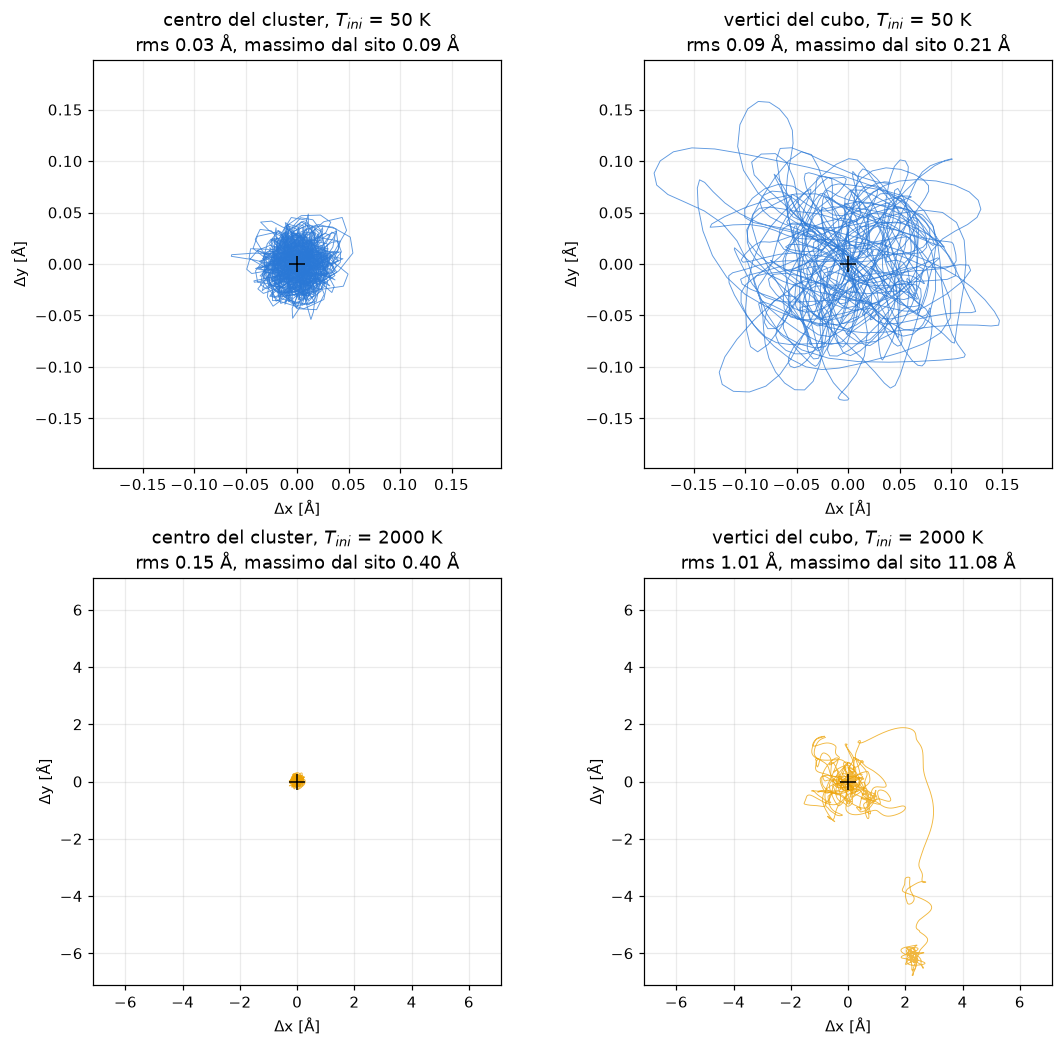

,rms centro [Å],rms vertici [Å],rapporto vertici / centro,"massimo dal sito, centro [Å]","massimo dal sito, vertici [Å]"
T_ini,,,,,
50 K,0.028,0.091,3.2,0.09,0.21
500 K,0.082,0.237,2.9,0.20,0.61
1000 K,0.116,0.508,4.4,0.31,1.91
2000 K,0.154,1.008,6.6,0.40,11.08


In [9]:
d_centro = np.linalg.norm(pos_min - pos_min.mean(axis=0), axis=1)
gruppi = {"centro del cluster": np.argsort(d_centro)[:4], "vertici del cubo": np.where(coord == 3)[0]}

rms, spost_max = {}, {}
for t in DT_OTT:
    frames = traiettorie[t]["frames"]
    prod = frames[int(round(T_TH_PS * 1000 / DT_OTT[t])):]
    r_atomo = np.sqrt(((prod - prod.mean(axis=0)) ** 2).sum(axis=-1).mean(axis=0))
    dal_sito = np.linalg.norm(frames - pos_min, axis=-1).max(axis=0)  # massimo nel run, per atomo
    rms[t] = {nome: r_atomo[idx].mean() for nome, idx in gruppi.items()}
    spost_max[t] = {nome: dal_sito[idx].max() for nome, idx in gruppi.items()}

fig, assi = plt.subplots(2, 2, figsize=(10, 9.4), constrained_layout=True)
for riga, t in zip(assi, (50.0, 2000.0)):
    frames = traiettorie[t]["frames"]
    estremo = max(np.abs(frames[:, idx, :2] - pos_min[idx, :2]).max() for idx in gruppi.values()) * 1.05
    for ax, (nome, idx) in zip(riga, gruppi.items()):
        for k in idx:
            d = frames[:, k, :2] - pos_min[k, :2]
            ax.plot(d[:, 0], d[:, 1], lw=0.6, color=COLORI[t], alpha=0.75)
        ax.plot(0, 0, "+", color="black", ms=10)
        ax.set(xlim=(-estremo, estremo), ylim=(-estremo, estremo), aspect="equal",
               xlabel="Δx [Å]", ylabel="Δy [Å]",
               title=f"{nome}, $T_{{ini}}$ = {t:g} K\nrms {rms[t][nome]:.2f} Å, "
                     f"massimo dal sito {spost_max[t][nome]:.2f} Å")
plt.show()

display(pd.DataFrame(
    {f"{t:g} K": {"rms centro [Å]": f"{rms[t]['centro del cluster']:.3f}",
                  "rms vertici [Å]": f"{rms[t]['vertici del cubo']:.3f}",
                  "rapporto vertici / centro": f"{rms[t]['vertici del cubo'] / rms[t]['centro del cluster']:.1f}",
                  "massimo dal sito, centro [Å]": f"{spost_max[t]['centro del cluster']:.2f}",
                  "massimo dal sito, vertici [Å]": f"{spost_max[t]['vertici del cubo']:.2f}"}
     for t in DT_OTT}
).T.rename_axis("T_ini").style.set_caption(
    "rms: ampiezza media delle oscillazioni attorno alla posizione media (3–10 ps); "
    "massimo dal sito: distanza massima dal sito di minimo nei 10 ps"))

**Commento.**

- **50 K:** tutti gli atomi vibrano attorno al proprio sito, con ampiezze di
  qualche centesimo di Å. I vertici oscillano circa **3 volte** più del
  centro: hanno solo 3 primi vicini invece di 12, quindi le molle che li
  trattengono sono meno e il potenziale attorno a loro è più morbido.
- **2000 K** ($\langle T\rangle\approx910$ K): gli atomi al **centro**
  vibrano ancora attorno al sito, con oscillazioni più ampie ma sempre
  piccole rispetto alla distanza tra primi vicini (2.94 Å). I **vertici**
  invece si allontanano dal sito di diversi Å (ultima colonna della tabella):
  non vibrano più attorno a una posizione fissa, ma si muovono sulla
  superficie. L'interno resta un solido, la superficie no.
- È lo stesso effetto che, nel §3, abbassa $\langle T\rangle$ sotto
  $T_\text{ini}/2$: gli atomi che lasciano il sito esplorano zone anarmoniche
  del potenziale.

## Riepilogo

In [10]:
riepilogo = pd.DataFrame(
    [
        ("1", "taglio netto, 50 K", f"Δt validi {testo_validi(punto1[50.0])}: ottimale {ottimale(punto1[50.0])}"),
        ("1", "taglio netto, 500 K", f"nessun Δt valido: δE/|⟨E⟩| = {sotto_fs[0.25]['dE_rel']:.1e} anche a 0.25 fs"),
        ("2", "P7 contro netto, 50 K", f"stesso Δt ottimale ({ottimale(punto2[50.0])}) e stesso ⟨T⟩"),
        ("2", "P7, 500 / 1000 / 2000 K",
         " / ".join(ottimale(punto2[t]) for t in (500.0, 1000.0, 2000.0))),
        ("3.0", "steepest descent", f"{iStep} iterazioni, ΔE = {e_min - energia[0]:.2f} eV, "
         f"spostamento massimo {np.linalg.norm(spost, axis=1).max():.2f} Å (vertici)"),
        ("3", "⟨T⟩ / (T_ini/2)", " / ".join(f"{np.mean([p['T_mean'] for p in punto3[t]]) / (t / 2):.2f}"
                                           for t in DT_OTT) + " (50 / 500 / 1000 / 2000 K)"),
        ("3", "traiettorie", "vertici più mobili del centro; a 2000 K la superficie si muove, l'interno no"),
    ],
    columns=["punto", "cosa", "risultato"],
).set_index("punto")
display(riepilogo.style.set_caption("Esercizio 1, punti 1–3"))

,cosa,risultato
punto,,
1,"taglio netto, 50 K",Δt validi 1–20 fs: ottimale 20 fs
1,"taglio netto, 500 K",nessun Δt valido: δE/|⟨E⟩| = 1.5e-04 anche a 0.25 fs
2,"P7 contro netto, 50 K",stesso Δt ottimale (20 fs) e stesso ⟨T⟩
2,"P7, 500 / 1000 / 2000 K",6 fs / 4 fs / 3 fs
3.0,steepest descent,"598 iterazioni, ΔE = -0.22 eV, spostamento massimo 0.05 Å (vertici)"
3,⟨T⟩ / (T_ini/2),1.01 / 1.03 / 1.00 / 0.91 (50 / 500 / 1000 / 2000 K)
3,traiettorie,"vertici più mobili del centro; a 2000 K la superficie si muove, l'interno no"
